In [1]:
include("../src/load_all.jl")

Loaded successfully.


In [ ]:
case_FVM = IsentropicCase.make_case(nx=40, ny=40, degree=0, OF=true, positivity=false, final_time=1, cfl=0.2)
solution_case_FVM = Solver.raw_solve_2d(case_FVM; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case_FVM.final_time/20)
(solution_case_FVM.time, solution_case_FVM.number_of_steps, solution_case_FVM.number_of_retries)
# 40 seconds

step=1 time=0.03703670354496429 dt=0.03703670354496429 retries=0
step=2 time=0.07408535434751456 dt=0.037048650802550265 retries=0
step=3 time=0.11115029778040572 dt=0.037064943432891156 retries=0
step=4 time=0.14821605448211994 dt=0.03706575670171421 retries=0
step=5 time=0.1852751702201515 dt=0.03705911573803154 retries=0
step=6 time=0.2223320352345451 dt=0.037056865014393585 retries=0
step=7 time=0.25939098237076463 dt=0.037058947136219524 retries=0
step=8 time=0.2964562858687883 dt=0.037065303498023665 retries=0
step=9 time=0.3335048108958794 dt=0.03704852502709111 retries=0
step=10 time=0.3705370948599094 dt=0.037032283964029994 retries=0
step=11 time=0.4075574837547362 dt=0.03702038889482683 retries=0
step=12 time=0.4445702627572038 dt=0.037012779002467605 retries=0
step=13 time=0.48157666442584895 dt=0.03700640166864517 retries=0
step=14 time=0.5185531157187383 dt=0.03697645129288938 retries=0
step=15 time=0.5555039994201108 dt=0.03695088370137248 retries=0
step=16 time=0.592433

(1.0, 28, 0)

In [4]:
Diagnostics.conservation_report(solution_case_FVM)

(initial_total_ls = [64.46798598878964, 32.87867285428263, 32.87867285428263, 22.778688382705695], final_total_ls = [64.46798598878941, 32.878672854282435, 32.87867285428245, 22.77868838270561], change_ls = [-2.2737367544323206e-13, -1.9184653865522705e-13, -1.7763568394002505e-13, -8.526512829121202e-14], boundary_change_ls = [-2.7222328023716975e-20, 6.6266699208872556e-18, 7.927530348953322e-18, 2.1168533059823446e-17], balance_error_ls = [-2.2737364822090404e-13, -1.9185316532514793e-13, -1.77643611470374e-13, -8.528629682427184e-14])

In [8]:
Diagnostics.smooth_error_norms(solution_case_FVM.state, case_FVM, solution_case_FVM.time)

(L1_ls = [0.004096843912314627, 0.0037459756069255145, 0.0037459756069255167, 0.0038478314437044477], L2_ls = [0.004830258436781082, 0.00455419082269996, 0.004554190822699963, 0.004731449514617931], Linf_ls = [0.016110408073291338, 0.015626931687137524, 0.015626931687137136, 0.01623383673531839], total_area = 157.91367041742893)

In [ ]:
display(Visualization.plot_mesh(solution_case_FVM.state,case_FVM.mesh))

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasedensity.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasedensity.gif")
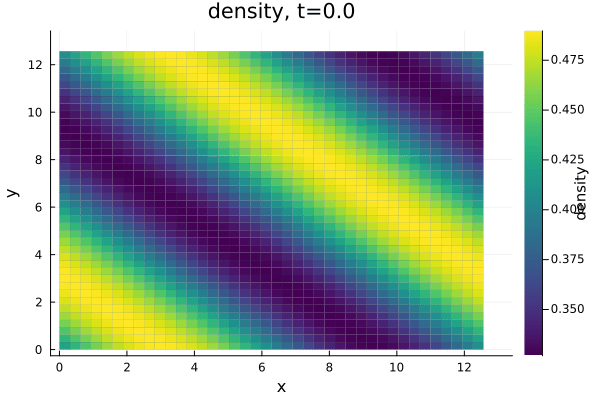

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasepressure.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasepressure.gif")
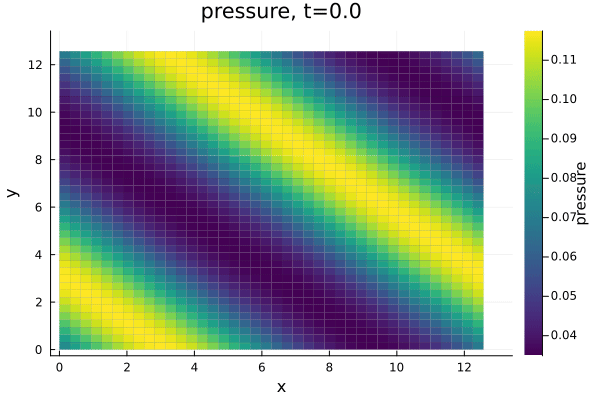

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasevelocity_x.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasevelocity_x.gif")
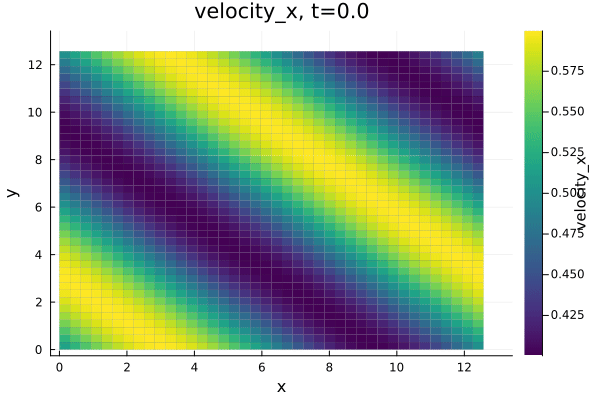

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\IsentropicCasevelocity_y.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\IsentropicCasevelocity_y.gif")
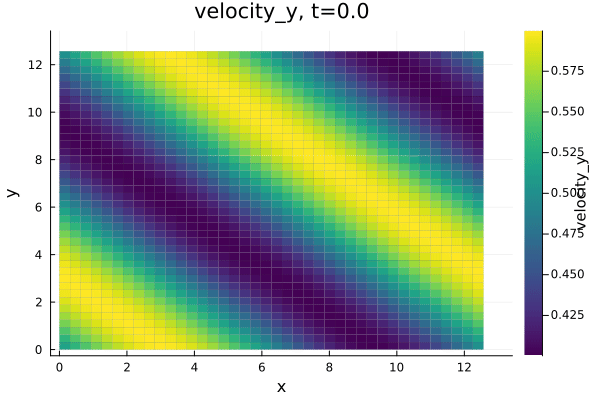

In [ ]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution_case_FVM,
        "../results/IsentropicCase$(field).gif";
        field = field,
        fps = 5,
    )
    display(gif_result)
end
# plot takes about 1 mins

In [11]:
function Isentropic_case_builder(nx, degree, final_time=1)
    
    if degree <= 1
        cfl = 0.5
    end
    if degree == 2
        cfl = 0.3
    end
    if degree == 3
        cfl = 0.1
    end 
    
    return IsentropicCase.make_case(
        nx = nx,
        degree = degree,
        final_time = final_time,
        cfl = 0.05,
    )
end

Isentropic_case_builder (generic function with 2 methods)

In [12]:
# Diagnostics.convergence_study_data
function convergence_study_data(case_builder; mesh_sizes_ls=[4, 8, 16], degree=2,
                        final_time=1, time_method=:RK4, dt_max=Inf)

    rows_ls = NamedTuple[]

    for nx in mesh_sizes_ls
        case = case_builder(nx, degree, final_time) # case::Discretization.DGCase
        solution = Solver.raw_solve_2d(case; time_method=time_method, dt_max=dt_max)
        errors = Diagnostics.smooth_error_norms(solution.state, case, solution.time)
        order_ls = fill(NaN, 4)
        if !isempty(rows_ls)
            previous = rows_ls[end]
            for component_index in 1:4
                if previous.L2_ls[component_index] > 0 && errors.L2_ls[component_index] > 0
                    order_ls[component_index] = log(previous.L2_ls[component_index] / errors.L2_ls[component_index]) / log(nx / previous.nx)
                end
            end
        end

        # first one just push 
        push!(rows_ls, (nx=nx, degree=degree, L1_ls=errors.L1_ls, L2_ls=errors.L2_ls,
                    Linf_ls=errors.Linf_ls, order_ls=order_ls,
                    number_of_steps=solution.number_of_steps, number_of_retries=solution.number_of_retries))
    end

    return rows_ls

end
converge_data = convergence_study_data(Isentropic_case_builder) # 36 Seconds

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [0.004395642611712015, 0.0039507172557761575, 0.003959650068691601, 0.00410227267701272], L2_ls = [0.006054888136377305, 0.005363256105994582, 0.00536296444546132, 0.005564703435969277], Linf_ls = [0.03808393703260149, 0.040003231034305864, 0.0400035921945604, 0.04451478879190329], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [0.0005340631376989458, 0.0005373557760145697, 0.0005335453917175913, 0.0005271133096690418], L2_ls = [0.0008206045911706109, 0.0008076745737862439, 0.0008077192682743987, 0.0008319106616269077], Linf_ls = [0.008325737118856091, 0.009523463570581703, 0.009522616500588998, 0.010849967339936595], order_ls = [2.8833411754313505, 2.7312631184274645, 2.7311048281802606, 2.741804291290495], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [7.418062423319679e-5, 7.295891129728892e-5, 7.271027022239787e-5, 7.080357777004782e

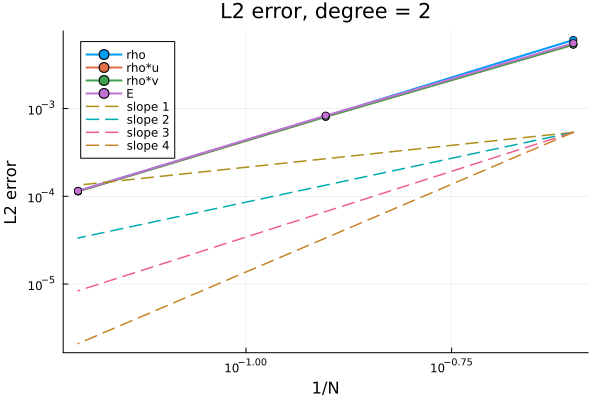

3-element Vector{NamedTuple}:
 (nx = 4, degree = 2, L1_ls = [0.004395642611712015, 0.0039507172557761575, 0.003959650068691601, 0.00410227267701272], L2_ls = [0.006054888136377305, 0.005363256105994582, 0.00536296444546132, 0.005564703435969277], Linf_ls = [0.03808393703260149, 0.040003231034305864, 0.0400035921945604, 0.04451478879190329], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 2, L1_ls = [0.0005340631376989458, 0.0005373557760145697, 0.0005335453917175913, 0.0005271133096690418], L2_ls = [0.0008206045911706109, 0.0008076745737862439, 0.0008077192682743987, 0.0008319106616269077], Linf_ls = [0.008325737118856091, 0.009523463570581703, 0.009522616500588998, 0.010849967339936595], order_ls = [2.8833411754313505, 2.7312631184274645, 2.7311048281802606, 2.741804291290495], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 2, L1_ls = [7.418062423319679e-5, 7.295891129728892e-5, 7.271027022239787e-5, 7.080357777004782e

In [13]:
Diagnostics.convergence_study_plot(converge_data)

In [14]:
converge_data = convergence_study_data(Isentropic_case_builder, mesh_sizes_ls=[4, 8, 16], degree=3,final_time=1, time_method=:SSPRK3, dt_max=Inf)
# 36 Seconds

3-element Vector{NamedTuple}:
 (nx = 4, degree = 3, L1_ls = [0.0011061334119290326, 0.0009916645956481766, 0.000990397610559388, 0.0009695693650513339], L2_ls = [0.0016052863550181527, 0.0013693551597690062, 0.0013692197511822283, 0.001275024019208653], Linf_ls = [0.02121567593153134, 0.014431877102534851, 0.014422371709486431, 0.011402523576626994], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 3, L1_ls = [9.328309296892975e-5, 9.1950018113714e-5, 9.30098914230472e-5, 9.445243565629736e-5], L2_ls = [0.0001459379777414287, 0.0001457971507554142, 0.00014579685111759208, 0.00014952605925269016], Linf_ls = [0.0019208077786356248, 0.0023899686001825904, 0.0023900357246909865, 0.0026776444608495875], order_ls = [3.459403399136423, 3.231462245385594, 3.231322542521508, 3.092055582272662], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 3, L1_ls = [6.662090809735492e-6, 6.729885449786294e-6, 6.753580566564245e-6, 6.5389154630

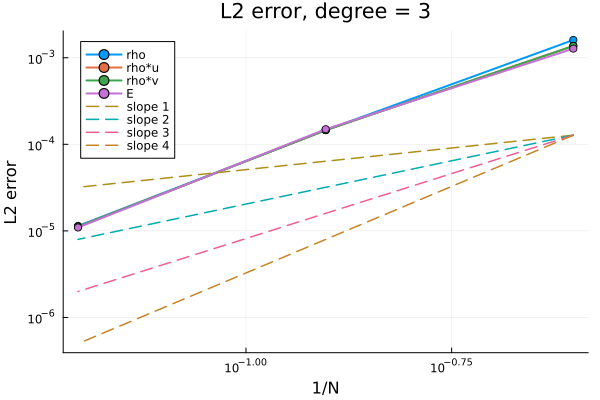

3-element Vector{NamedTuple}:
 (nx = 4, degree = 3, L1_ls = [0.0011061334119290326, 0.0009916645956481766, 0.000990397610559388, 0.0009695693650513339], L2_ls = [0.0016052863550181527, 0.0013693551597690062, 0.0013692197511822283, 0.001275024019208653], Linf_ls = [0.02121567593153134, 0.014431877102534851, 0.014422371709486431, 0.011402523576626994], order_ls = [NaN, NaN, NaN, NaN], number_of_steps = 11, number_of_retries = 0)
 (nx = 8, degree = 3, L1_ls = [9.328309296892975e-5, 9.1950018113714e-5, 9.30098914230472e-5, 9.445243565629736e-5], L2_ls = [0.0001459379777414287, 0.0001457971507554142, 0.00014579685111759208, 0.00014952605925269016], Linf_ls = [0.0019208077786356248, 0.0023899686001825904, 0.0023900357246909865, 0.0026776444608495875], order_ls = [3.459403399136423, 3.231462245385594, 3.231322542521508, 3.092055582272662], number_of_steps = 22, number_of_retries = 0)
 (nx = 16, degree = 3, L1_ls = [6.662090809735492e-6, 6.729885449786294e-6, 6.753580566564245e-6, 6.5389154630

In [15]:
Diagnostics.convergence_study_plot(converge_data)